In [22]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, roc_auc_score

import joblib


In [23]:
df = pd.read_csv("E:/final yr project/readmission/backend/chronic_kidney_disease_dataset.csv")   # change filename if needed
df.head()


,Age,Gender,Ethnicity,BMI,Serum_Creatinine,eGFR,BUN,Albumin,UACR,Proteinuria,...,Calcium,HbA1c,Fasting_Glucose,Diabetes_Status,Systolic_BP,Diastolic_BP,Smoking_Status,Alcohol_Consumption,CKD_Severity,Readmitted
0,71,Female,White,41.2,3.24,60.1,78.6,4.1,2690.8,1,...,8.0,7.7,302.1,1,164,74,No,Moderate,2,1
1,34,Female,Black,32.1,2.11,60.4,22.7,3.0,432.4,0,...,8.4,13.4,280.7,0,187,104,No,Heavy,2,1
2,80,Male,Other,23.2,5.93,40.0,68.9,2.6,1755.9,0,...,8.2,5.1,234.7,1,121,63,Yes,Heavy,2,1
3,40,Female,Asian,42.1,4.58,94.7,67.3,2.3,2352.2,1,...,10.2,7.4,77.9,1,186,107,Yes,Moderate,2,1
4,43,Male,Other,18.8,0.84,111.5,72.1,4.1,824.6,1,...,7.8,11.5,284.1,0,165,117,No,Heavy,1,0


In [24]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  5000 non-null   int64  
 1   Gender               5000 non-null   object 
 2   Ethnicity            5000 non-null   object 
 3   BMI                  5000 non-null   float64
 4   Serum_Creatinine     5000 non-null   float64
 5   eGFR                 5000 non-null   float64
 6   BUN                  5000 non-null   float64
 7   Albumin              5000 non-null   float64
 8   UACR                 5000 non-null   float64
 9   Proteinuria          5000 non-null   int64  
 10  Potassium            5000 non-null   float64
 11  Sodium               5000 non-null   float64
 12  Phosphate            5000 non-null   float64
 13  Calcium              5000 non-null   float64
 14  HbA1c                5000 non-null   float64
 15  Fasting_Glucose      5000 non-null   f

In [25]:
df.isnull().sum()



Age                       0
Gender                    0
Ethnicity                 0
BMI                       0
Serum_Creatinine          0
eGFR                      0
BUN                       0
Albumin                   0
UACR                      0
Proteinuria               0
Potassium                 0
Sodium                    0
Phosphate                 0
Calcium                   0
HbA1c                     0
Fasting_Glucose           0
Diabetes_Status           0
Systolic_BP               0
Diastolic_BP              0
Smoking_Status            0
Alcohol_Consumption    1655
CKD_Severity              0
Readmitted                0
dtype: int64

In [26]:
df.describe()


,Age,BMI,Serum_Creatinine,eGFR,BUN,Albumin,UACR,Proteinuria,Potassium,Sodium,Phosphate,Calcium,HbA1c,Fasting_Glucose,Diabetes_Status,Systolic_BP,Diastolic_BP,CKD_Severity,Readmitted
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54.478400,31.50554,3.772578,62.871020,43.956540,3.728860,1499.008740,0.497000,4.762440,140.04206,4.538220,9.262000,9.270520,209.686540,0.495800,144.561200,89.550200,1.869000,0.660000
std,20.091746,7.74630,1.845572,33.462876,20.891457,1.010102,865.073744,0.500041,1.009349,8.60021,1.452676,1.010004,2.761303,81.655836,0.500032,26.048354,17.089374,0.355337,0.473756
min,20.000000,18.00000,0.600000,5.000000,7.000000,2.000000,5.600000,0.000000,3.000000,125.00000,2.000000,7.500000,4.500000,70.000000,0.000000,100.000000,60.000000,0.000000,0.000000
25%,37.000000,24.80000,2.170000,34.000000,26.100000,2.900000,764.300000,0.000000,3.900000,132.70000,3.300000,8.400000,6.900000,139.200000,0.000000,122.000000,75.000000,2.000000,0.000000
50%,54.000000,31.50000,3.770000,62.400000,44.400000,3.700000,1484.450000,0.000000,4.800000,140.00000,4.600000,9.300000,9.200000,209.100000,0.000000,145.000000,90.000000,2.000000,1.000000
75%,72.000000,38.10000,5.360000,92.300000,61.900000,4.600000,2250.925000,1.000000,5.600000,147.50000,5.800000,10.100000,11.700000,281.700000,1.000000,167.000000,104.000000,2.000000,1.000000
max,89.000000,45.00000,7.000000,120.000000,80.000000,5.500000,2999.700000,1.000000,6.500000,155.00000,7.000000,11.000000,14.000000,350.000000,1.000000,189.000000,119.000000,2.000000,1.000000


In [27]:
X = df.drop(["Readmitted", "CKD_Severity"], axis=1)
y = df["Readmitted"]



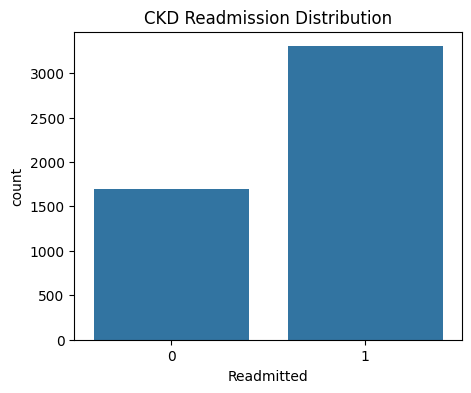

In [7]:
plt.figure(figsize=(5,4))
sns.countplot(x="Readmitted", data=ckd_df)
plt.title("CKD Readmission Distribution")
plt.show()


In [28]:
categorical_features = [
    "Gender",
    "Ethnicity",
    "Smoking_Status",
    "Alcohol_Consumption",
    "Proteinuria",
    "Diabetes_Status"
]

numeric_features = [
    col for col in X.columns if col not in categorical_features
]



In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [31]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'BMI',
                                                   'Serum_Creatinine', 'eGFR',
                                                   'BUN', 'Albumin', 'UACR',
                                                   'Potassium', 'Sodium',
                                                   'Phosphate', 'Calcium',
                                                   'HbA1c', 'Fasting_Glucose',
                                                   'Systolic_BP',
                                                   'Diastolic_BP']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Ethnicity',
                                                   'Smoking_Status',
                                                   'Alcohol_Consumption',
                                                   'Proteinuria',
                                                   'Diabetes_Status'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [32]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'BMI',
                                                   'Serum_Creatinine', 'eGFR',
                                                   'BUN', 'Albumin', 'UACR',
                                                   'Potassium', 'Sodium',
                                                   'Phosphate', 'Calcium',
                                                   'HbA1c', 'Fasting_Glucose',
                                                   'Systolic_BP',
                                                   'Diastolic_BP']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Ethnicity',
                                                   'Smoking_Status',
                                                   'Alcohol_Consumption',
                                                   'Proteinuria',
                                                   'Diabetes_Status'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [33]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print("-" * 40)


Logistic Regression
Accuracy: 0.659
ROC-AUC: 0.601608734402852
----------------------------------------
Random Forest
Accuracy: 0.661
ROC-AUC: 0.5911697860962567
----------------------------------------


In [34]:
best_model = rf_model


In [35]:
joblib.dump(
    best_model.named_steps["preprocessor"],
    "ckd_preprocessor.pkl"
)

joblib.dump(
    best_model.named_steps["classifier"],
    "ckd_model.pkl"
)



['ckd_model.pkl']

In [36]:
ckd_preprocessor = joblib.load("ckd_preprocessor.pkl")
ckd_model = joblib.load("ckd_model.pkl")

sample = X.iloc[[0]]
sample_processed = ckd_preprocessor.transform(sample)

print("Prediction:", ckd_model.predict(sample_processed))
print("Probability:", ckd_model.predict_proba(sample_processed))


Prediction: [1]
Probability: [[0.1 0.9]]


In [39]:


ckd_preprocessor = joblib.load("ckd_preprocessor.pkl")
ckd_model = joblib.load("ckd_model.pkl")




In [42]:
patient = {
    "Age": 62,
    "Gender": "Male",
    "Ethnicity": "Asian",
    "BMI": 28.5,
    "Systolic_BP": 150,
    "Diastolic_BP": 95,
    "Serum_Creatinine": 3.2,
    "eGFR": 26,
    "BUN": 58,
    "Albumin": 2.9,
    "UACR": 680,
    "Proteinuria": 1,
    "HbA1c": 8.1,
    "Fasting_Glucose": 168,
    "Potassium": 5.6,
    "Sodium": 131,
    "Phosphate": 5.1,
    "Calcium": 8.0,
    "Smoking_Status": "Former",
    "Alcohol_Consumption": "None",
    "Diabetes_Status": "Yes"   # ✅ REQUIRED
}

df = pd.DataFrame([patient])

# ✅ enforce exact training order
df = df[ckd_preprocessor.feature_names_in_]

X = ckd_preprocessor.transform(df)


In [43]:
import pandas as pd
import joblib

# ================= LOAD SAVED FILES ================= #

ckd_preprocessor = joblib.load("ckd_preprocessor.pkl")
ckd_model = joblib.load("ckd_model.pkl")

# ================= SAMPLE PATIENT ================= #

patient = {
    "Age": 62,
    "Gender": "Male",
    "Ethnicity": "Asian",
    "BMI": 28.5,
    "Serum_Creatinine": 3.2,
    "eGFR": 26,
    "BUN": 58,
    "Albumin": 2.9,
    "UACR": 680,
    "Proteinuria": 1,
    "Potassium": 5.6,
    "Sodium": 131,
    "Phosphate": 5.1,
    "Calcium": 8.0,
    "HbA1c": 8.1,
    "Fasting_Glucose": 168,
    "Diabetes_Status": "Yes",
    "Systolic_BP": 150,
    "Diastolic_BP": 95,
    "Smoking_Status": "Former",
    "Alcohol_Consumption": "None"
}

# ================= PREPROCESS ================= #

df = pd.DataFrame([patient])

# IMPORTANT: enforce exact training column order
df = df[ckd_preprocessor.feature_names_in_]

X = ckd_preprocessor.transform(df)

# ================= PREDICTIONS ================= #

severity_class = ckd_model.predict(X)[0]
readmission_prob = ckd_model.predict_proba(X)[0][1] * 100

# ================= MAPPINGS ================= #

def get_ckd_severity_label(cls):
    return {
        0: "Mild CKD",
        1: "Moderate CKD",
        2: "Severe CKD"
    }[cls]

def get_readmission_label(prob):
    if prob <= 30:
        return "Low Risk of Readmission"
    elif prob <= 60:
        return "Moderate Risk – Monitor Closely"
    else:
        return "High Risk – Re-admission Recommended"

severity = get_ckd_severity_label(severity_class)
readmission = get_readmission_label(readmission_prob)

# ================= OUTPUT ================= #

print("=" * 45)
print("CKD PATIENT TEST RESULT")
print("=" * 45)
print(f"Predicted CKD Severity     : {severity}")
print(f"Readmission Probability   : {readmission_prob:.2f}%")
print(f"Readmission Risk          : {readmission}")
print("=" * 45)


CKD PATIENT TEST RESULT
Predicted CKD Severity     : Moderate CKD
Readmission Probability   : 89.00%
Readmission Risk          : High Risk – Re-admission Recommended


In [21]:
severity_map = {
    0: "Mild CKD",
    1: "Moderate CKD",
    2: "Severe CKD"
}

lifestyle_map = {
    "Mild CKD": [
        "Maintain healthy diet",
        "Regular exercise",
        "Annual kidney check-up"
    ],
    "Moderate CKD": [
        "Low sodium & protein diet",
        "Strict BP & glucose control",
        "Frequent kidney monitoring"
    ],
    "Severe CKD": [
        "Immediate nephrologist consultation",
        "Prepare for dialysis if advised",
        "Strict fluid & diet restriction"
    ]
}

insurance_map = {
    "Mild CKD": "Basic Renal Care Plan",
    "Moderate CKD": "Advanced Kidney Care Plan",
    "Severe CKD": "Comprehensive Renal Protection Plan"
}

severity = severity_map[sev_class]

print("="*45)
print("CKD PATIENT RESULT")
print("="*45)
print("Predicted CKD Severity :", severity)
print("Readmission Risk       :", "HIGH" if readm_class == 1 else "LOW")
print(f"Readmission Probability: {readm_prob:.2f}%\n")

print("Lifestyle Suggestions:")
for tip in lifestyle_map[severity]:
    print("-", tip)

print("\nRecommended Insurance Plan:")
print("-", insurance_map[severity])
print("="*45)


CKD PATIENT RESULT
Predicted CKD Severity : Severe CKD
Readmission Risk       : HIGH
Readmission Probability: 70.80%

Lifestyle Suggestions:
- Immediate nephrologist consultation
- Prepare for dialysis if advised
- Strict fluid & diet restriction

Recommended Insurance Plan:
- Comprehensive Renal Protection Plan
